In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

%matplotlib inline

In [2]:
import pandas as pd

df = pd.read_csv('data.csv')

df.head()

,Make,Model,Year,Engine Fuel Type,Engine HP,Engine Cylinders,Transmission Type,Driven_Wheels,Number of Doors,Market Category,Vehicle Size,Vehicle Style,highway MPG,city mpg,Popularity,MSRP
0,BMW,1 Series M,2011,premium unleaded (required),335.0,6.0,MANUAL,rear wheel drive,2.0,"Factory Tuner,Luxury,High-Performance",Compact,Coupe,26,19,3916,46135
1,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Convertible,28,19,3916,40650
2,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,High-Performance",Compact,Coupe,28,20,3916,36350
3,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Coupe,28,18,3916,29450
4,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Luxury,Compact,Convertible,28,18,3916,34500


In [3]:
## Data Preparation

In [4]:
df.columns = df.columns.str.lower().str.replace(' ', '_')

In [5]:
df.dtypes
strings = list(df.dtypes[df.dtypes == 'str'].index)

In [6]:
for col in strings:
    df[col] = df[col].str.lower().str.replace(' ', '_')

df.head()

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,msrp
0,bmw,1_series_m,2011,premium_unleaded_(required),335.0,6.0,manual,rear_wheel_drive,2.0,"factory_tuner,luxury,high-performance",compact,coupe,26,19,3916,46135
1,bmw,1_series,2011,premium_unleaded_(required),300.0,6.0,manual,rear_wheel_drive,2.0,"luxury,performance",compact,convertible,28,19,3916,40650
2,bmw,1_series,2011,premium_unleaded_(required),300.0,6.0,manual,rear_wheel_drive,2.0,"luxury,high-performance",compact,coupe,28,20,3916,36350
3,bmw,1_series,2011,premium_unleaded_(required),230.0,6.0,manual,rear_wheel_drive,2.0,"luxury,performance",compact,coupe,28,18,3916,29450
4,bmw,1_series,2011,premium_unleaded_(required),230.0,6.0,manual,rear_wheel_drive,2.0,luxury,compact,convertible,28,18,3916,34500


In [7]:
## EDA

In [8]:
for col in df.columns:
    print(col)
    print(list(df[col].unique()[:5]))
    print(df[col].nunique())
    print()

make
['bmw', 'audi', 'fiat', 'mercedes-benz', 'chrysler']
48

model
['1_series_m', '1_series', '100', '124_spider', '190-class']
914

year
[np.int64(2011), np.int64(2012), np.int64(2013), np.int64(1992), np.int64(1993)]
28

engine_fuel_type
['premium_unleaded_(required)', 'regular_unleaded', 'premium_unleaded_(recommended)', 'flex-fuel_(unleaded/e85)', 'diesel']
10

engine_hp
[np.float64(335.0), np.float64(300.0), np.float64(230.0), np.float64(320.0), np.float64(172.0)]
356

engine_cylinders
[np.float64(6.0), np.float64(4.0), np.float64(5.0), np.float64(8.0), np.float64(12.0)]
9

transmission_type
['manual', 'automatic', 'automated_manual', 'direct_drive', 'unknown']
5

driven_wheels
['rear_wheel_drive', 'front_wheel_drive', 'all_wheel_drive', 'four_wheel_drive']
4

number_of_doors
[np.float64(2.0), np.float64(4.0), np.float64(3.0), np.float64(nan)]
3

market_category
['factory_tuner,luxury,high-performance', 'luxury,performance', 'luxury,high-performance', 'luxury', 'performance']
71


<Axes: xlabel='msrp', ylabel='Count'>

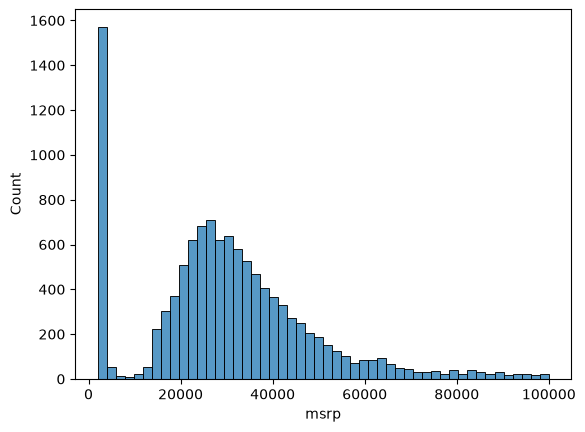

In [9]:
sns.histplot(df.msrp[df.msrp < 100000], bins = 50)

<Axes: xlabel='msrp', ylabel='Count'>

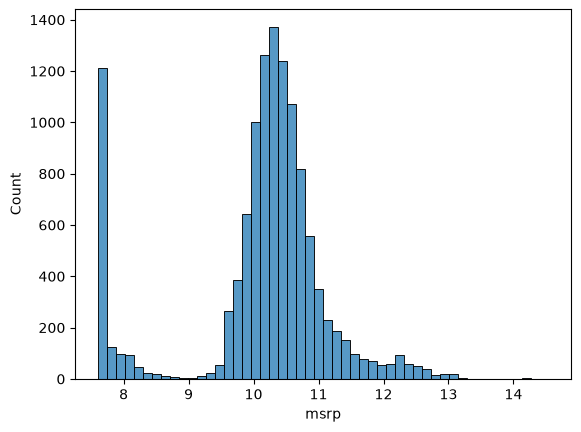

In [10]:
price_logs = np.log1p(df.msrp)
sns.histplot(price_logs, bins = 50)

In [11]:
df.isnull().sum()

make                    0
model                   0
year                    0
engine_fuel_type        3
engine_hp              69
engine_cylinders       30
transmission_type       0
driven_wheels           0
number_of_doors         6
market_category      3742
vehicle_size            0
vehicle_style           0
highway_mpg             0
city_mpg                0
popularity              0
msrp                    0
dtype: int64

In [12]:
## Validation Framework

In [13]:
n = len(df)

n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

print(f"{n} {n_train} {n_val} {n_test}")

11914 7150 2382 2382


In [14]:
idx = np.arange(n)
np.random.seed(2)
np.random.shuffle(idx)

df_train = df.iloc[idx[:n_train]].reset_index(drop=True)
df_val = df.iloc[idx[n_train:n_train+n_val]].reset_index(drop=True)
df_test = df.iloc[idx[n_train+n_val:]].reset_index(drop=True)

In [15]:
y_train = np.log1p(df_train.msrp.values)
y_val = np.log1p(df_val.msrp.values)
y_test = np.log1p(df_test.msrp.values)

del df_train['msrp']
del df_val['msrp']
del df_test['msrp']

In [16]:
# Regressione lineare per una sola feature
xi = [453, 11, 86]
w0 = 7.17
w = [0.01, 0.04, 0.002]

def linear_regression(xi):
    n = len(xi)

    pred = w0

    for j in range(n):
        pred = pred + w[j] * xi[j]

    return pred

lr = linear_regression(xi)
np.expm1(lr)


np.float64(222347.2221101062)

In [17]:
def dot(xi, w):
    n = len(xi)

    res = 0.0

    for j in range(n):
        res += xi[j] * w[j]

    return res

def linear_regression2(xi):
    return w0 + dot(xi, w)

linear_regression2(xi)

12.312000000000001

In [18]:
w_new = [w0] + w
def linear_regression3(xi):
    xi = [1] + xi
    return dot(xi, w_new)

linear_regression3(xi)

12.312

In [19]:
x1  = [1, 148, 24, 1385]
x2  = [1, 132, 25, 2031]
x10 = [1, 453, 11, 86]

X = [x1, x2, x10]
X = np.array(X)

w0 = 7.17
w = [0.01, 0.04, 0.002]
w_new = [w0] + w

def linear_regression4(X):
    return X.dot(w_new)

linear_regression4(X)

array([12.38 , 13.552, 12.312])

In [ ]:
## Funzione che trova i pesi di un modello di regressione lineare
def train_linear_regression(X, y):
    ## Inserisco colonna per il bias term (w0) che servirà dopo nella 
    ## moltiplicazione per predire il valore con la regressione lineare
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX_inv = np.linalg.inv(XTX)

    ## Verifica correttezza matrice di Gram (se il prodotto è un'identità è corretta)
    #XTX.dot(XTX_inv).round(1)

    w_full = XTX_inv.dot(X.T).dot(y)

    return w_full[0], w_full[1:]

In [56]:
base = ['engine_hp', 'engine_cylinders', 'highway_mpg', 'city_mpg', 'popularity']

categorical_variables = ['make', 'engine_fuel_type', 'transmission_type', 'driven_wheels',
    'market_category', 'vehicle_size', 'vehicle_style']

categories = {}

for c in categorical_variables:
    categories[c] = list(df_train[c].value_counts().head().index)


## Prepara la matrice delle feature prima di darla in pasto al modello
## Creo anche delle nuove feature per aiutare ancora di più il modello con la predizione 
## Riempio i valori NaN con degli 0 (Sarebbe più corretto riempirli con la media del valore in quella colonna)
def prepare_X(df):
    df = df.copy()
    features = base.copy()
    
    df['age'] = 2017 - df.year
    features.append('age')

    for c, values in categories.items():
        for v in values:
            df['%s_%s' % (c, v)] = (df[c] == v).astype('int')
            features.append('%s_%s' % (c, v))


    for v in [2, 3, 4]:
        df['num_doors_%s' % v] = (df.number_of_doors == v).astype('int')
        features.append('num_doors_%s' % v)

    df_num = df[features]
    df_num = df_num.fillna(0)

    return df_num.values

In [58]:
def train_linear_regression_reg(X, y, r = 0.001):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX = XTX + r * np.eye(XTX.shape[0])

    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)

    return w_full[0], w_full[1:]

In [64]:
def rmse(y, y_pred):
    se = (y - y_pred) ** 2
    mse = se.mean()
    return np.sqrt(mse)

In [65]:
## Scelta del parametro per la regolarizzazione
for r in [10, 1, 0.1, 0.001, 0.0001, 0.00001, 0.0]:
    X_train = prepare_X(df_train)
    w0, w = train_linear_regression_reg(X_train, y_train, r)

    X_val = prepare_X(df_val)
    y_pred = w0 + X_val.dot(w)
    score = rmse(y_val, y_pred)

    print(r, w0, score)

10 4.283980108947261 0.47014569321013217
1 5.634896668508489 0.45722043179965133
0.1 6.191208663203348 0.4565692763006195
0.001 6.284262062634642 0.4565175084560206
0.0001 6.256420242187221 0.45651706456245533
1e-05 6.210941588476202 0.4565170112770296
0.0 -6.06223039198761e+16 171.4646042825832


0.4565175084560206


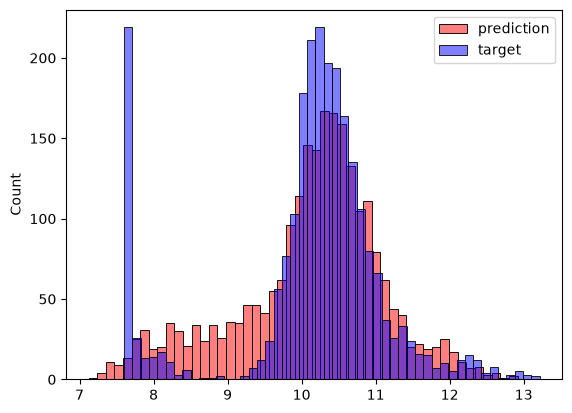

In [66]:
r = 0.001
X_train = prepare_X(df_train)
w0, w = train_linear_regression_reg(X_train, y_train, r)

## Verifichiamo l'errore commesso con i dati di validazione
X_val = prepare_X(df_val)
y_pred = w0 + X_val.dot(w)

print(rmse(y_val, y_pred))

sns.histplot(y_pred, label='prediction', color='red', alpha=0.5, bins=50)
sns.histplot(y_val, label='target', color='blue',  alpha=0.5, bins=50)
plt.legend()

In [67]:
df_full_train = pd.concat([df_train, df_val]).reset_index(drop=True)
y_full_train = np.concatenate([y_train, y_val])

X_full_train = prepare_X(df_full_train)
w0, w = train_linear_regression_reg(X_full_train, y_full_train, r)

X_test = prepare_X(df_test)
y_pred = w0 + X_test.dot(w)
rmse(y_test, y_pred)


np.float64(0.45177493077296066)

In [76]:
## Predizione del prezzo di una macchina
car = df_test.iloc[20].to_dict()

df_car = pd.DataFrame([car])
X_car = prepare_X(df_car)
y_pred_car = w0 + X_car.dot(w)
y_pred_car = y_pred_car[0]
print(f'Prezzo predetto: {np.expm1(y_pred_car)} Prezzo reale: {np.expm1(y_test[20])}')

Prezzo predetto: 34983.195972499525 Prezzo reale: 35000.00000000001
